### Lab 5
#### Name: Shreenidhi Thakur
#### Section: C
#### Roll no.: 18
#### Date of performance: 25/08/2026

##### KNN

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, GridSearchCV, cross_val_score, StratifiedKFold)

from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_curve, roc_auc_score)
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [ ]:
# load dataset
df=pd.read_csv("diabetes (6).csv")
print("Shape:",df.shape)

Shape: (768, 9)


In [ ]:
print("First 5 rows:")
display(df.head())

First 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
print("Last 5 rows:")
display(df.tail())

Last 5 rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
763,10,101,76,48,180,32.9,0.171,63,0
764,2,122,70,27,0,36.8,0.340,27,0
765,5,121,72,23,112,26.2,0.245,30,0
766,1,126,60,0,0,30.1,0.349,47,1
767,1,93,70,31,0,30.4,0.315,23,0


In [ ]:
print("Dataset shape:",df.shape)
print("Number of rows:",df.shape[0])
print("Number of colunms:",df.shape[1])

Dataset shape: (768, 9)
Number of rows: 768
Number of colunms: 9


In [ ]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [ ]:
print("Data Types:\n")
print(df.dtypes)

Data Types:

Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object


In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [ ]:
missing=df.isnull().sum()

print("Missing values:")
print(missing)

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


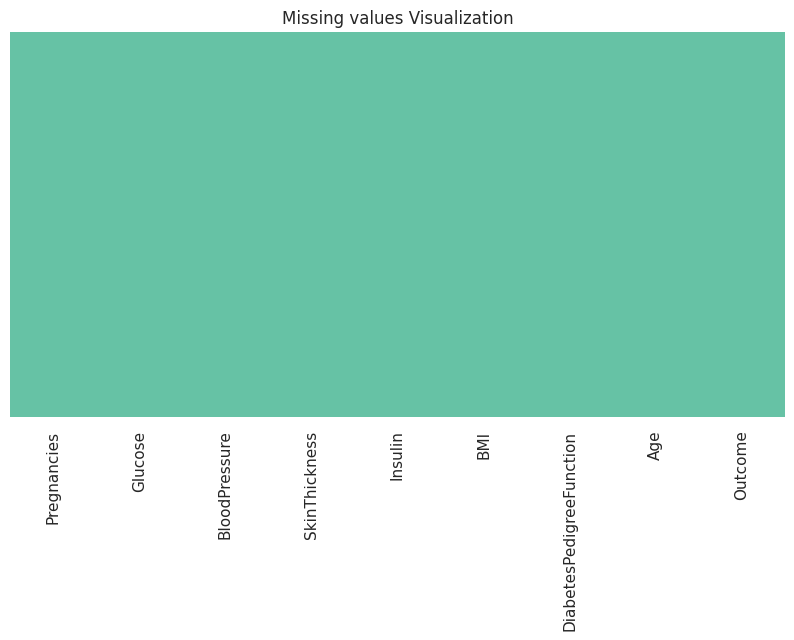

In [ ]:
plt.figure(figsize=(10,5))

sns.heatmap(df.isnull(),
            cbar=False,
            yticklabels=False,
            cmap="Set2")

plt.title("Missing values Visualization")
plt.show()

In [ ]:
duplicate_count=df.duplicated().sum()

print("Duplicate rows:")
print(duplicate_count)

Duplicate rows:
0


In [ ]:
if duplicate_count>0:
    df.drop_duplicates().reset_index(drop=True)

print("New shape:",df.shape)

New shape: (768, 9)


In [ ]:
print(df["Outcome"].value_counts())

Outcome
0    500
1    268
Name: count, dtype: int64


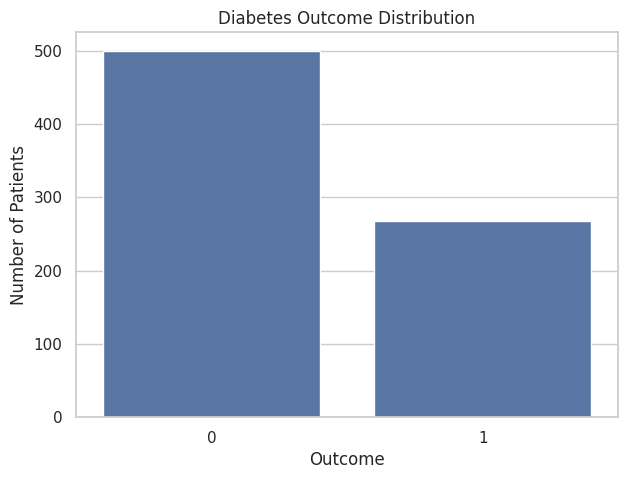

In [ ]:
plt.figure(figsize=(7,5))

sns.countplot(
    x="Outcome",
    data=df,
    )

plt.title("Diabetes Outcome Distribution")
plt.xlabel("Outcome")
plt.ylabel("Number of Patients")

plt.show()

In [ ]:
target_percentage=(
    df["Outcome"].value_counts(normalize=True).sort_index()*100
)

print(target_percentage)

Outcome
0    65.104167
1    34.895833
Name: proportion, dtype: float64


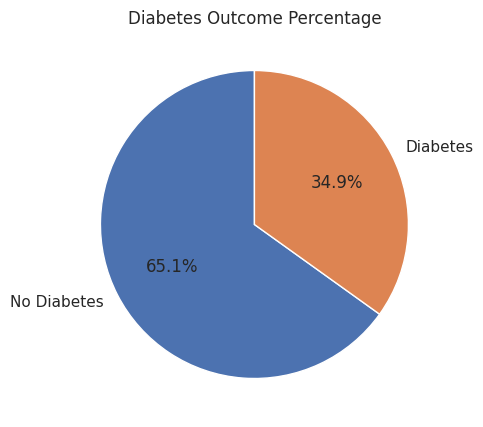

In [ ]:
plt.figure(figsize=(7,5))

plt.pie(
    target_percentage,
    labels=["No Diabetes","Diabetes"],
    autopct="%.1f%%",
    startangle=90,
    )

plt.title("Diabetes Outcome Percentage")

plt.show()

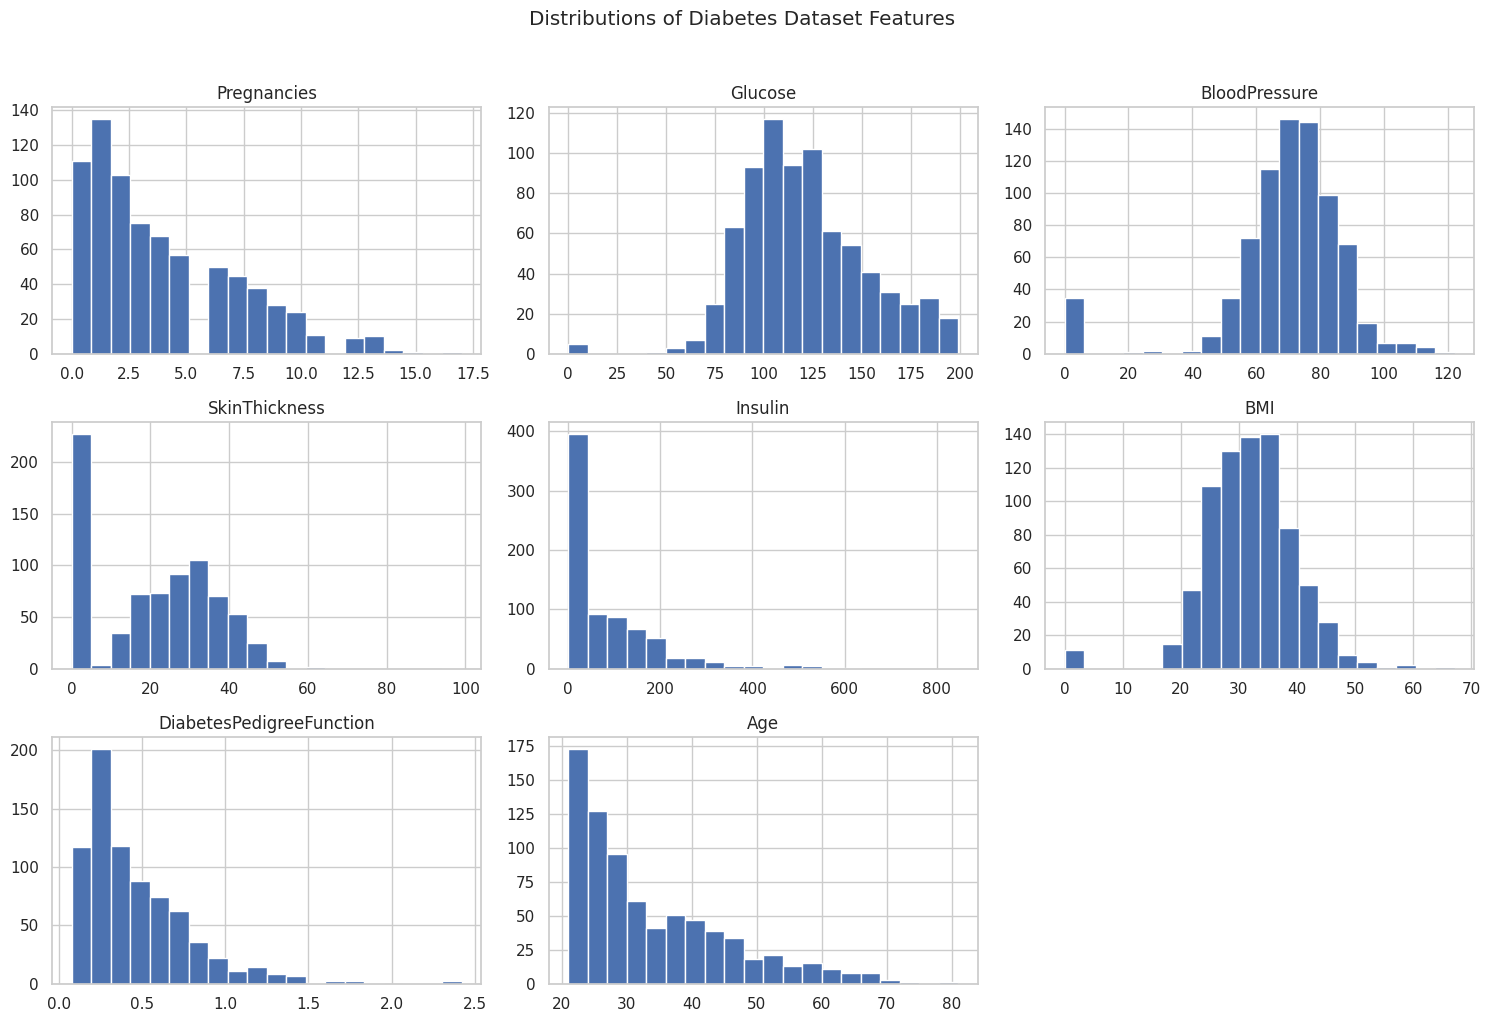

In [ ]:
features=df.drop(columns="Outcome").columns

df[features].hist(figsize=(15,10),bins=20)

plt.suptitle("Distributions of Diabetes Dataset Features",y=1.02)

plt.tight_layout()
plt.show()

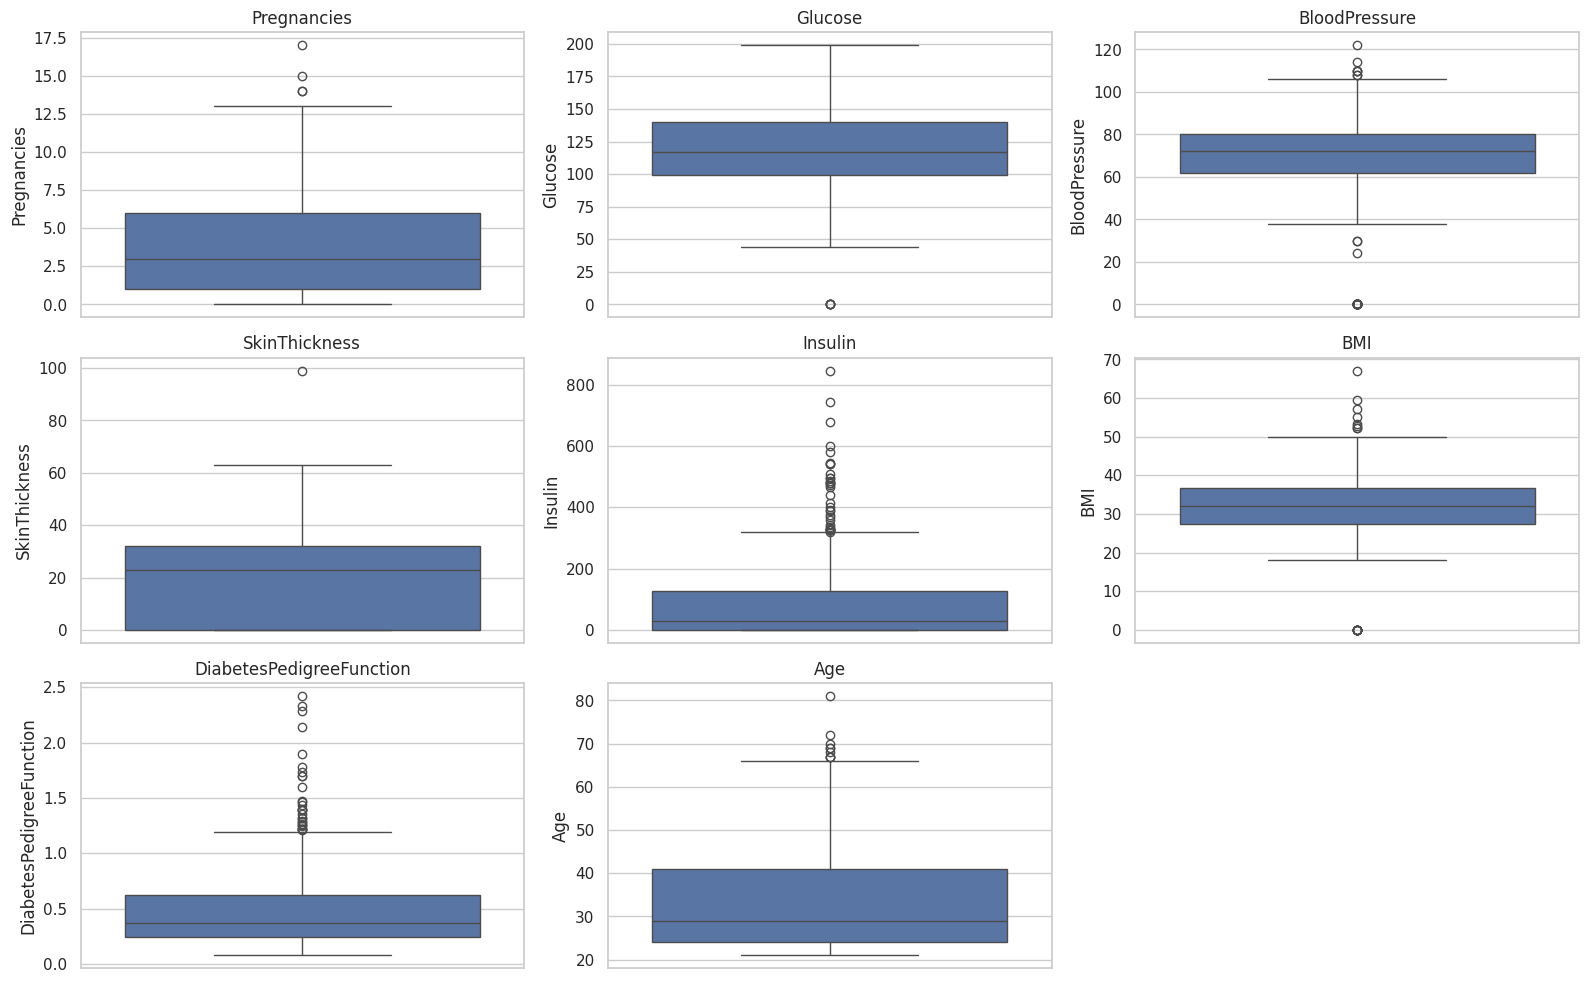

In [ ]:
plt.figure(figsize=(16,10))

for i ,col in enumerate(features,1):
    plt.subplot(3,3,i)

    sns.boxplot(y=df[col])
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:
zero_columns=["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]

zero_counts=(df[zero_columns]==0).sum()

print("Zero values count:")
print(zero_counts)

Zero values count:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


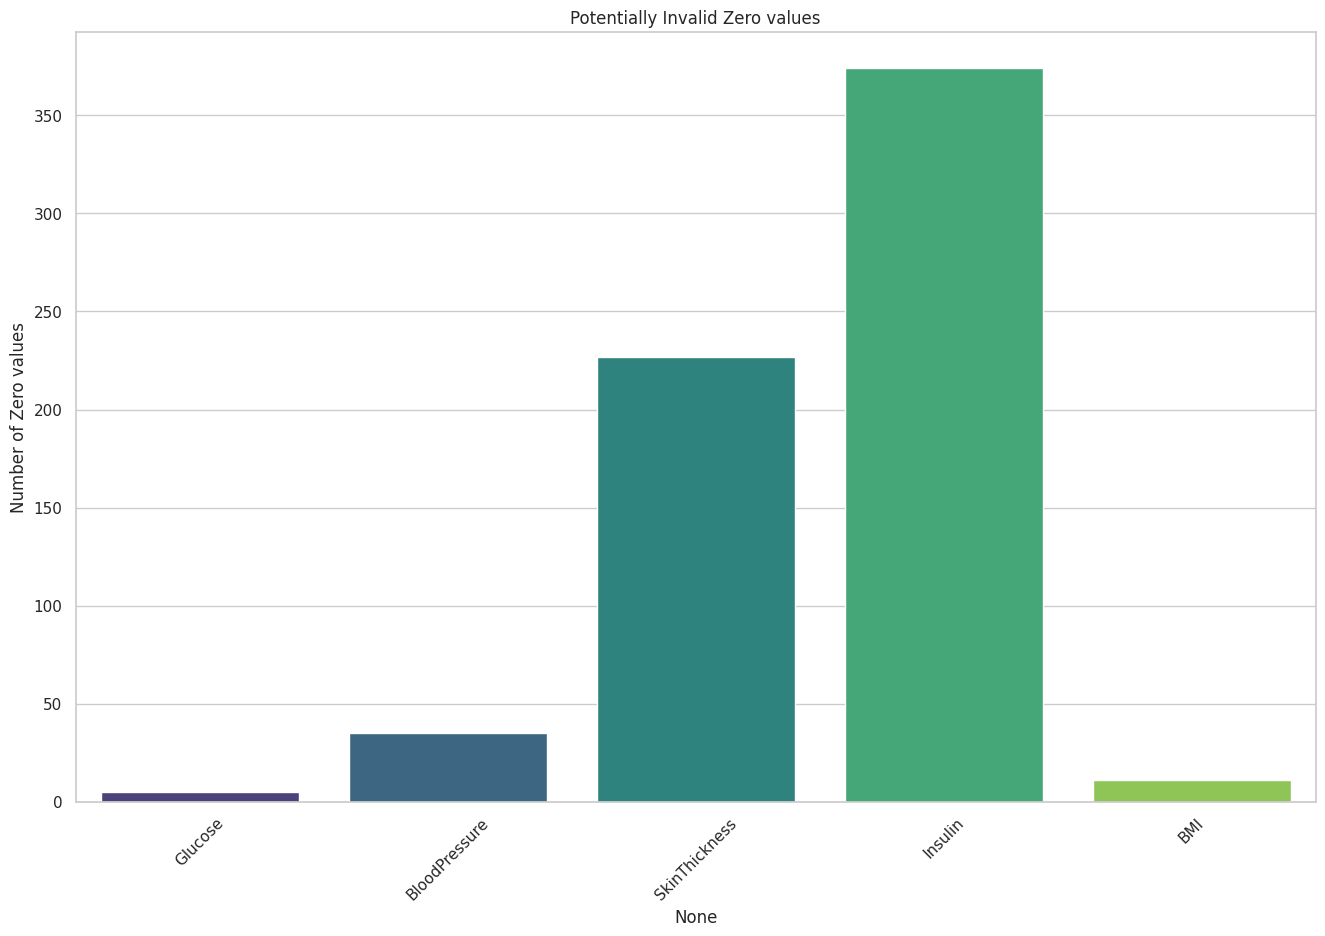

In [ ]:
plt.figure(figsize=(16,10))

sns.barplot(x=zero_counts.index,y=zero_counts.values, palette="viridis")

plt.xticks(rotation=45)
plt.ylabel("Number of Zero values")
plt.title("Potentially Invalid Zero values")

plt.show()

In [ ]:
df_clean=df.copy()

df_clean[zero_columns]=df_clean[zero_columns].replace(0,np.nan)

print("Missing values after replacing invalid zeros:")
print(df_clean.isnull().sum())

Missing values after replacing invalid zeros:
Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


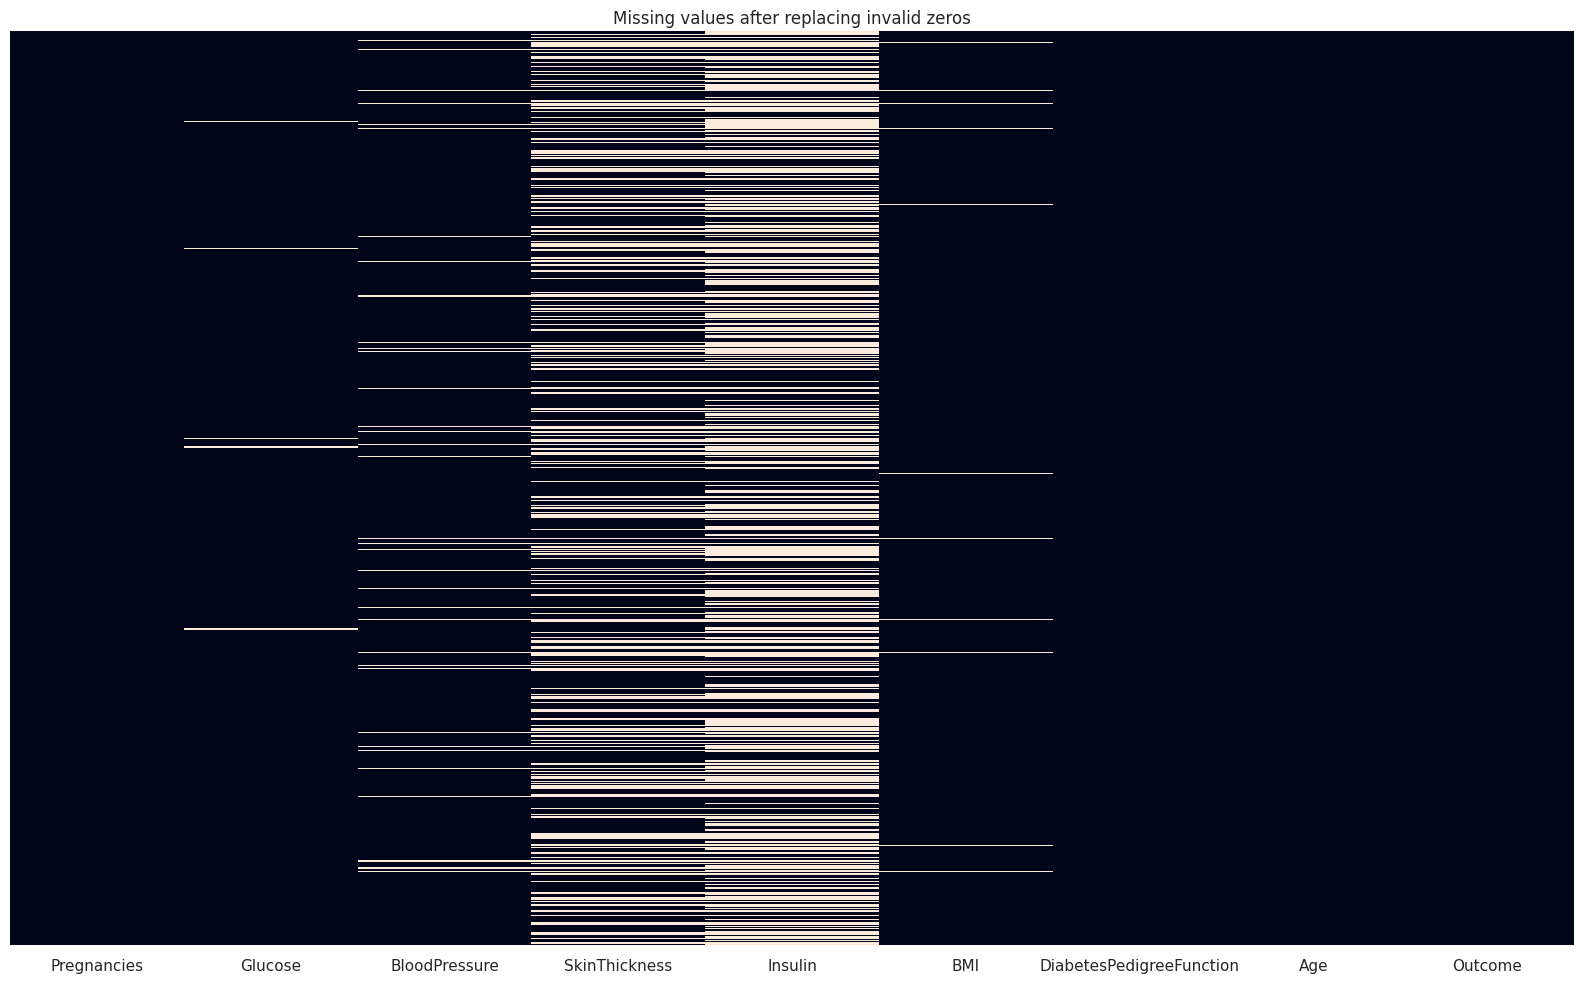

In [ ]:
plt.figure(figsize=(16,10))

sns.heatmap(df_clean.isnull(),
            cbar=False,
            yticklabels=False,
            )

plt.title("Missing values after replacing invalid zeros")

plt.tight_layout()
plt.show()

In [ ]:
for col in zero_columns:

  df_clean[col]=df_clean[col].fillna(df_clean[col].median())

print("Missing values after filling with median imputation:")
print(df_clean.isnull().sum())

Missing values after filling with median imputation:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


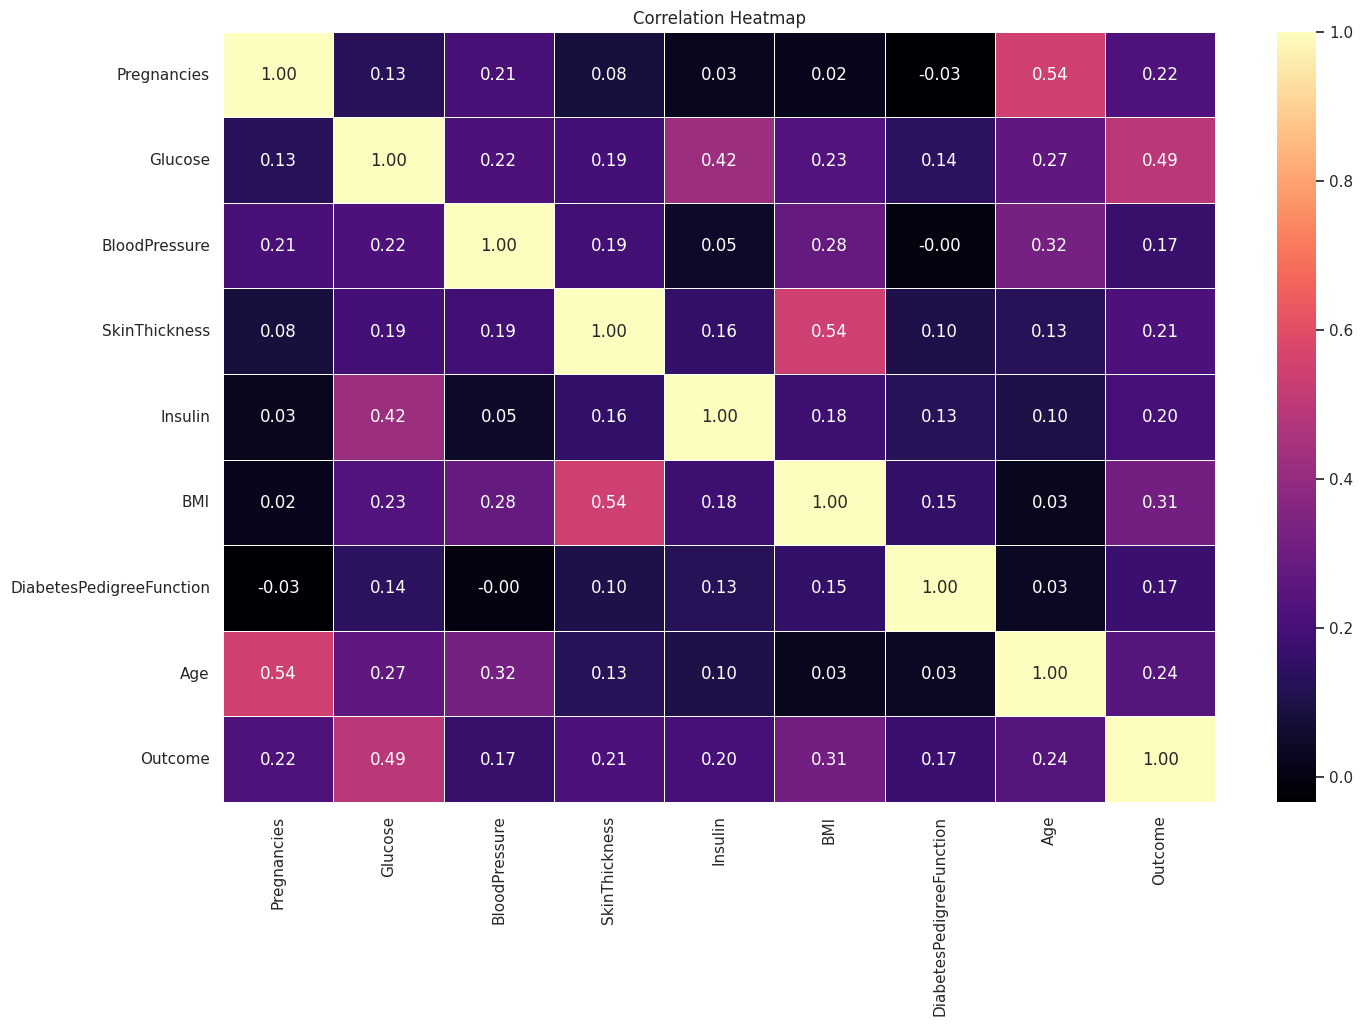

In [ ]:
plt.figure(figsize=(16,10))

correlation=df_clean.corr()

sns.heatmap(correlation,
            annot=True,
            cmap="magma",
            linewidths=0.5,
            fmt=".2f",
            )

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
target_corr=(df_clean.corr()["Outcome"].drop("Outcome").sort_values())

print(target_corr)

BloodPressure               0.165723
DiabetesPedigreeFunction    0.173844
Insulin                     0.203790
SkinThickness               0.214873
Pregnancies                 0.221898
Age                         0.238356
BMI                         0.312038
Glucose                     0.492782
Name: Outcome, dtype: float64


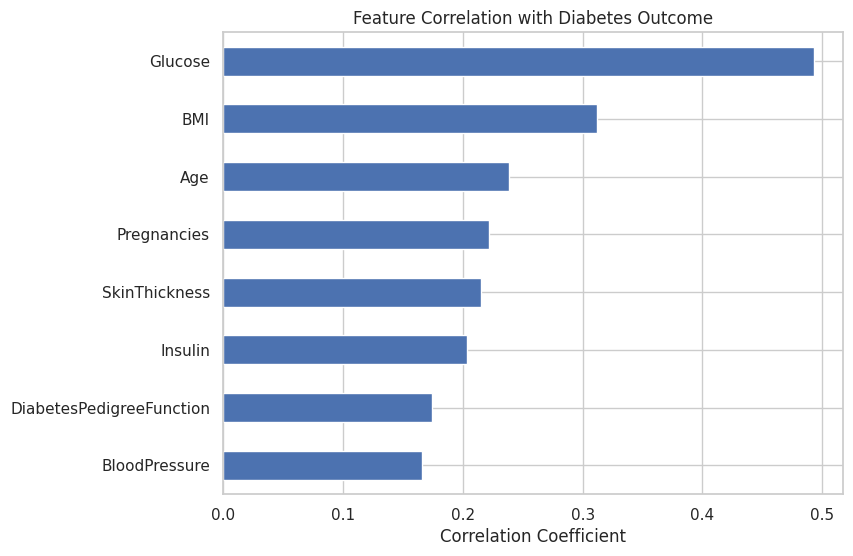

In [ ]:
plt.figure(figsize=(8,6))

target_corr.plot(kind="barh")

plt.title("Feature Correlation with Diabetes Outcome")
plt.xlabel("Correlation Coefficient")

plt.show()

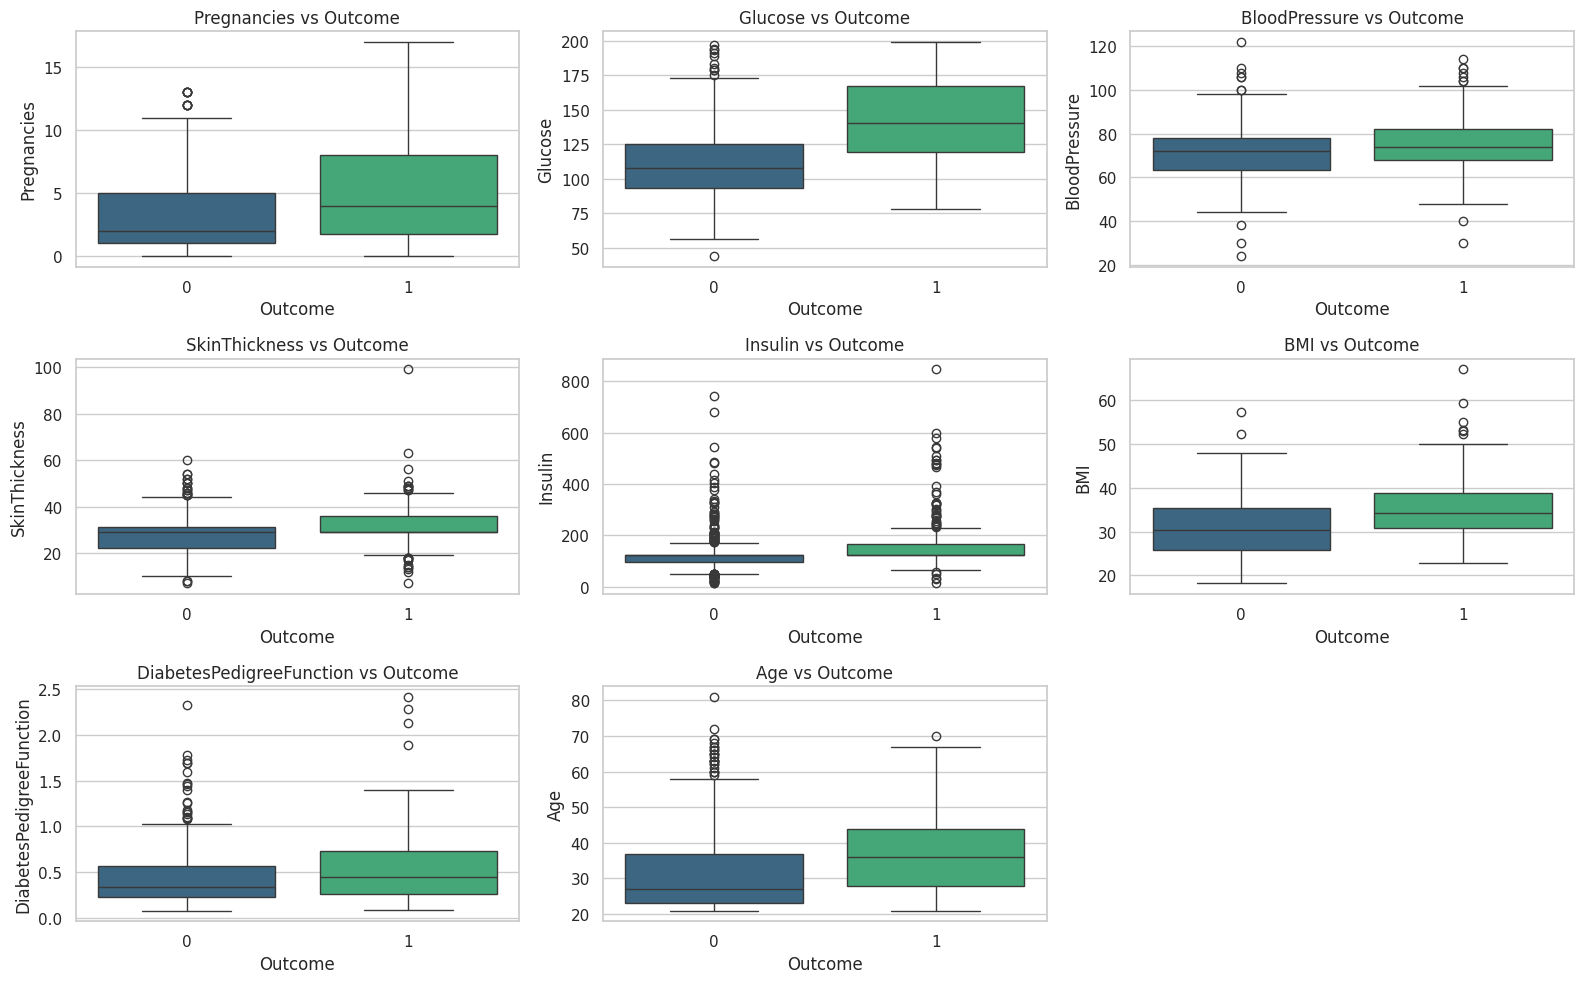

In [ ]:
plt.figure(figsize=(16,10))

for i,col in enumerate(features,1):
    plt.subplot(3,3,i)

    sns.boxplot(data=df_clean,x="Outcome",y=col,palette="viridis")
    plt.title(f"{col} vs Outcome")

plt.tight_layout()
plt.show()

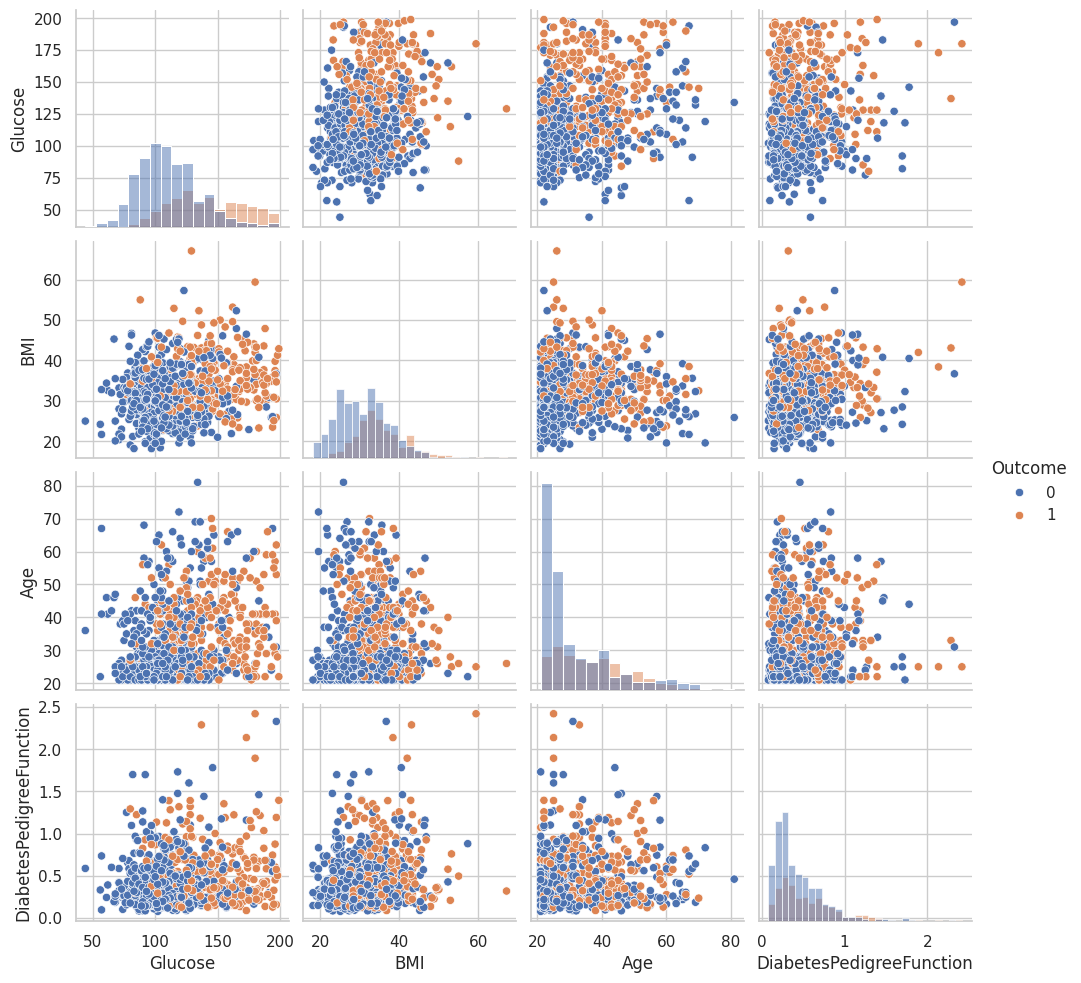

In [ ]:
selected_features=["Glucose","BMI","Age","DiabetesPedigreeFunction","Outcome"]

sns.pairplot(df_clean[selected_features],hue="Outcome",diag_kind="hist")

plt.show()

#### Algorithm

In [ ]:
X=df_clean.drop(columns="Outcome")
y=df_clean["Outcome"]

print("X Shape",X.shape)
print("y Shape",y.shape)

X Shape (768, 8)
y Shape (768,)


In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("X_train Shape:",X_train.shape[0])
print("X_test Shape:",X_test.shape[0])

X_train Shape: 614
X_test Shape: 154


In [ ]:
print("Training Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Distribution:")
print(y_test.value_counts(normalize=True))

Training Distribution:
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64

Testing Distribution:
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


In [ ]:
scaler=StandardScaler()

X_train_scaled=scaler.fit_transform(X_train)

X_test_scaled=scaler.transform(X_test)

print("Scaling completed")

Scaling completed


In [ ]:
scaler.fit_transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
scaler.transform(X_test)

array([[ 0.85252995,  1.16484536, -0.8288433 , ..., -0.71933141,
        -0.46562514,  0.63400979],
       [ 1.69054875, -1.66920722,  2.88630463, ...,  0.42561436,
        -0.49253293,  1.24533587],
       [-0.54416805,  0.01253827,  0.23262754, ...,  0.48215489,
         0.09943846, -0.58864236],
       ...,
       [-0.54416805, -1.23319913, -1.89031414, ..., -0.56384494,
         3.73497988, -0.67597466],
       [ 0.01451115,  1.94343123,  0.40953934, ...,  0.63764135,
        -0.55531777, -0.15198088],
       [-0.82350765, -1.57577692,  0.40953934, ...,  0.1005063 ,
        -0.08293657, -1.02530385]])

In [ ]:
comparison = pd.DataFrame({
    "Original Mean": X_train.mean(),
    "Original Standard Deviation": X_train.std(),
    "Scaled Mean": X_train_scaled.mean(axis=0),
    "Scaled Standard Deviation": X_train_scaled.std(axis=0)
})

display(comparison)

,Original Mean,Original Standard Deviation,Scaled Mean,Scaled Standard Deviation
Pregnancies,3.819218,3.314148,-6.943414e-17,1.0
Glucose,121.671010,30.003794,-1.099374e-16,1.0
BloodPressure,72.140065,12.275119,3.095606e-16,1.0
SkinThickness,29.042345,8.891855,-3.471707e-17,1.0
Insulin,137.705212,78.764767,-4.339634e-18,1.0
BMI,32.446743,6.824142,-1.148556e-15,1.0
DiabetesPedigreeFunction,0.477428,0.330300,-1.099374e-16,1.0
Age,33.366450,11.833438,-1.084908e-16,1.0


In [ ]:
K=5

In [ ]:
knn=KNeighborsClassifier(n_neighbors=K)

knn.fit(X_train_scaled,y_train)

print("KNN model trained successfully")

KNN model trained successfully


In [ ]:
y_pred=knn.predict(X_test_scaled)

print("Prediction:")
print(y_pred[:20])

Prediction:
[1 0 0 1 0 0 0 1 0 1 0 1 0 0 0 1 1 0 1 0]


In [ ]:
y_prob = knn.predict_proba(X_test_scaled)[:,1]

print("Prediction Probabilities:")
print(y_prob[:20])

Prediction Probabilities:
[0.6 0.2 0.2 0.6 0.  0.2 0.2 0.8 0.  0.6 0.4 0.6 0.  0.  0.  0.6 0.8 0.
 1.  0.2]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Accurracy: {accuracy:.4}")

Accurracy: 0.7532


In [ ]:
precision = precision_score(y_test, y_pred)

print(f"Precision: {precision:.4f}")

Precision: 0.6600


In [ ]:
recall = recall_score(y_test, y_pred)

print(f"Recall: {recall:.4f}")

Recall: 0.6111


In [ ]:
f1 = f1_score(y_test, y_pred)

print(f"F1 Score: {f1:.4f}")

F1 Score: 0.6346


In [ ]:
print(classification_report(y_test, y_pred, target_names=["No Diabetes", "Diabetes"]))

              precision    recall  f1-score   support

 No Diabetes       0.80      0.83      0.81       100
    Diabetes       0.66      0.61      0.63        54

    accuracy                           0.75       154
   macro avg       0.73      0.72      0.72       154
weighted avg       0.75      0.75      0.75       154



In [ ]:
cm = confusion_matrix(y_test,y_pred)


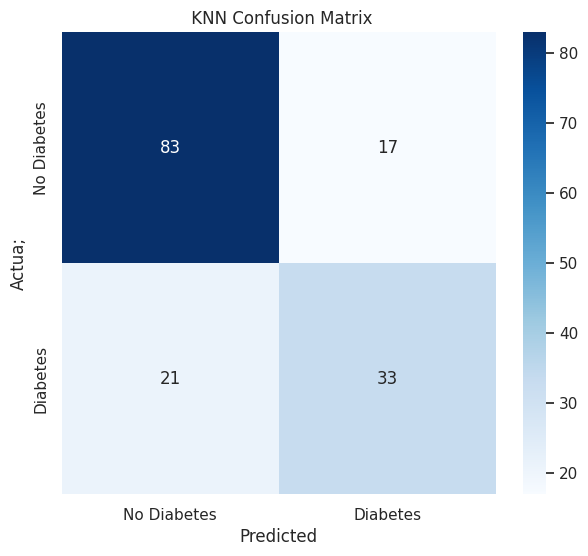

In [ ]:
plt.figure(figsize=(7,6))

sns.heatmap(cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["No Diabetes","Diabetes"],
            yticklabels=["No Diabetes","Diabetes"],
            )

plt.xlabel("Predicted")
plt.ylabel("Actua;")
plt.title(" KNN Confusion Matrix")

plt.show()

In [ ]:
k_values=range(1,31)

train_accuracy=[]
test_accuracy=[]

for k in k_values:
  model=KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train_scaled,y_train)

  train_accuracy.append(model.score(X_train_scaled,y_train))
  test_accuracy.append(model.score(X_test_scaled,y_test))

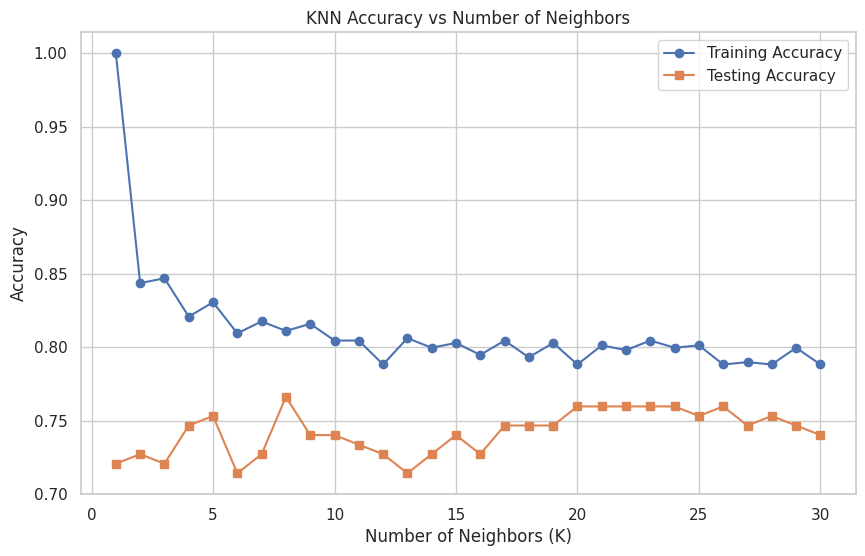

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(k_values,train_accuracy,marker="o",label="Training Accuracy")
plt.plot(k_values,test_accuracy,marker="s",label="Testing Accuracy")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("KNN Accuracy vs Number of Neighbors")
plt.legend()

plt.show()

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_scores=[]

for k in range(1,31):
  model=KNeighborsClassifier(n_neighbors=k)
  scores=cross_val_score(model,X_train_scaled,y_train,cv=cv,scoring="accuracy")
  cv_scores.append(scores.mean())

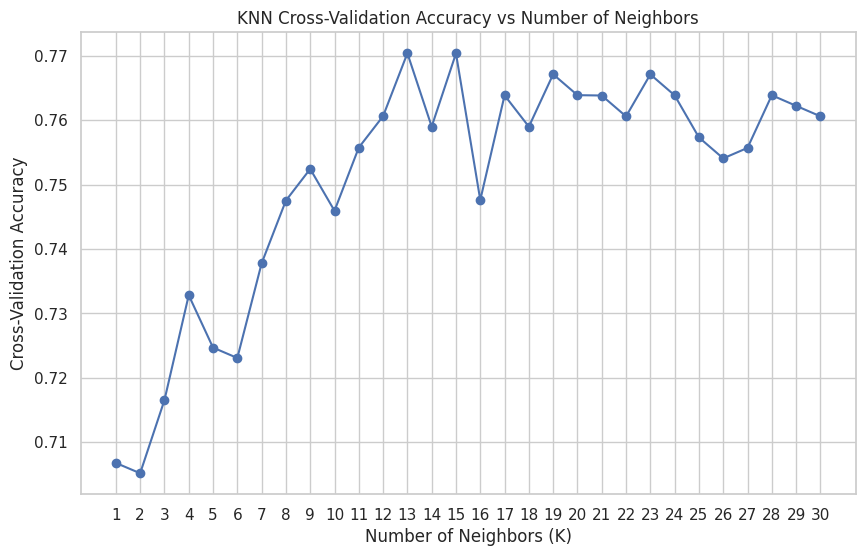

In [ ]:
plt.figure(figsize=(10,6))

plt.plot(range(1,31),cv_scores,marker="o")

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Cross-Validation Accuracy")
plt.title("KNN Cross-Validation Accuracy vs Number of Neighbors")
plt.xticks(range(1,31))

plt.show()


In [ ]:
best_k_cv=np.argmax(cv_scores)

print("Best K value based on 5 fold cv:",best_k_cv)
print("Best cv accuracy:",max(cv_scores))

Best K value based on 5 fold cv: 12
Best cv accuracy: 0.7703718512594963


In [ ]:
param_grid={"n_neighbors":list(range(3, 31, 2)), "weights":["uniform", "distance"],
              "metric":["euclidean", "manhattan", "minkowski"], "p":[1,2]}

In [ ]:
grid_search= GridSearchCV(estimator=KNeighborsClassifier(), param_grid=param_grid, cv=5, scoring="accuracy",n_jobs=-1)

grid_search.fit(X_train_scaled,y_train)
print("Grid search completed successfully!")

Grid search completed successfully!


In [ ]:
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation score:")
print(grid_search.best_score_)

Best parameters:
{'metric': 'euclidean', 'n_neighbors': 19, 'p': 1, 'weights': 'uniform'}

Best cross-validation score:
0.7769025723044115


In [ ]:
best_knn= grid_search.best_estimator_
print(best_knn)

KNeighborsClassifier(metric='euclidean', n_neighbors=19, p=1)
